1. Цветовая коррекция изображений
    1. Коррекция с опорным цветом
    2. Серый мир
    3. По виду функции преобразования
2. Яркостная коррекция в интерактивном режиме по виду функции преобразования(необязательное дополнительное задание)
    1. График функции кусочно линейный
    2. График функции интерполируется сплайном
3. Коррекция на основе гистограммы
    1. Нормализация гистограммы
    2. Эквализация гистограммы

In [1]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
from ipywidgets import interact, IntSlider
from scipy.interpolate import CubicSpline

In [2]:
def make_lut(func):
  lut = np.zeros(256, dtype=np.uint8)
  for v in range(256):
    lut[v] = np.clip(np.round(func(v)), 0, 255)
  return lut

In [12]:
def apply_luts(img, luts):
  result = np.zeros_like(img)
  for c in range(3):
    result[:, :, c] = cv2.LUT(img[:, :, c], luts[c])
  return result

In [14]:
def plot_luts(luts, labels=("R", "G", "B"), colors=("red", "green", "blue")):
  plt.figure(figsize=(4, 4))
  for lut, label, color in zip(luts, labels, colors):
    plt.plot(range(256), lut, label=label, color=color)
  plt.plot([0, 255], [0, 255], "--", color="gray")
  plt.xlim(0, 255)
  plt.ylim(0, 255)
  plt.xlabel("Входная яркость")
  plt.ylabel("Выходная яркость")
  plt.legend()
  plt.grid()
  plt.show()

In [8]:
def show_images(images, titles):
  plt.figure(figsize=(6 * len(images), 5))
  for i in range(len(images)):
    plt.subplot(1, len(images), i + 1)
    plt.imshow(images[i], cmap="gray", vmin=0, vmax=255)
    plt.title(titles[i])
    plt.axis("off")
  plt.show()

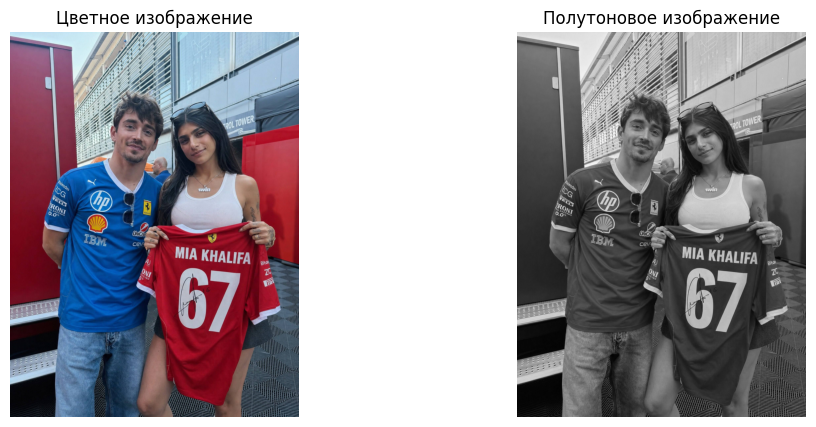

In [26]:
image = cv2.imread("image.jpg", cv2.IMREAD_COLOR_RGB)
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

show_images([image, gray], ["Цветное изображение", "Полутоновое изображение"])

1. Цветовая коррекция изображений
    1. Коррекция с опорным цветом

Опорный цвет на изображении: [185.1 192.3 205.2]
Каким он должен быть: [255, 255, 255]


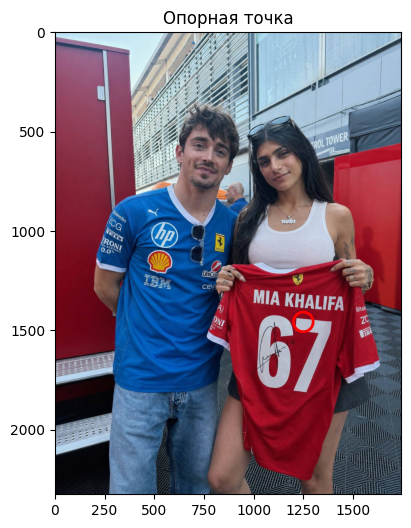

In [33]:
ref_x, ref_y = 1250, 1457
radius = 5

patch = image[ref_y - radius : ref_y + radius + 1, ref_x - radius : ref_x + radius + 1]
ref_color = [patch[:, :, c].mean() for c in range(3)]
target_color = [255, 255, 255]

print("Опорный цвет на изображении:", np.round(ref_color, 1))
print("Каким он должен быть:", target_color)

plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.scatter(ref_x, ref_y, s=200, facecolors="none", edgecolors="red", linewidths=2)
plt.title("Опорная точка")
plt.show()

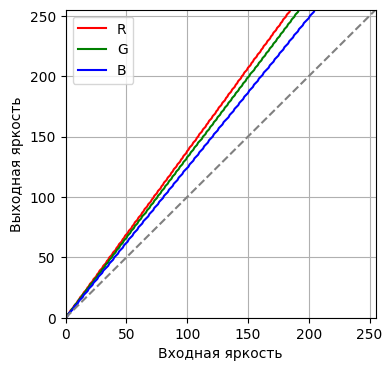

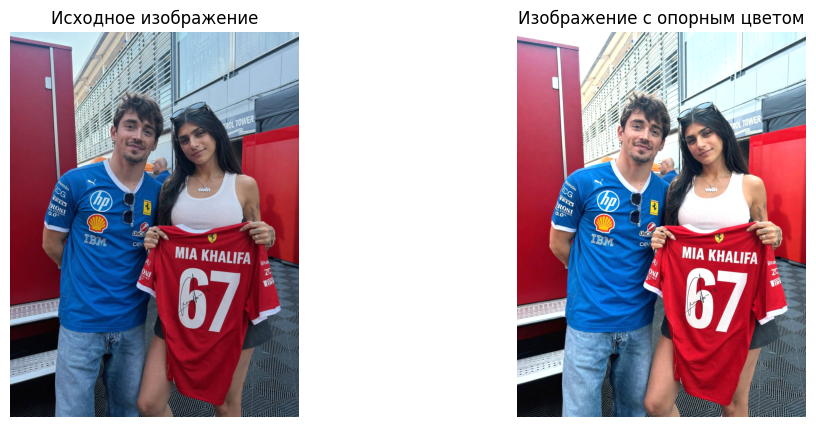

In [34]:
reference_luts = [make_lut(lambda v: v * target_color[c] / ref_color[c]) for c in range(3)]
reference_image = apply_luts(image, reference_luts)

plot_luts(reference_luts)
show_images([image, reference_image], ["Исходное изображение", "Изображение с опорным цветом"])

2. Серый мир

Средние R, G, B до: [109.2  91.3 112. ]
Средние R, G, B после: [104.2 103.8 104.1]


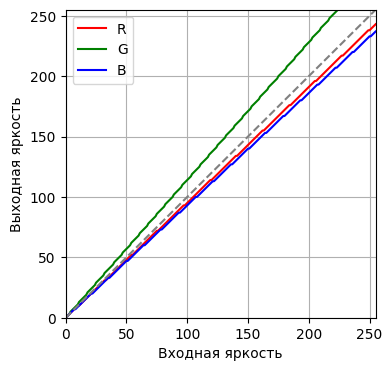

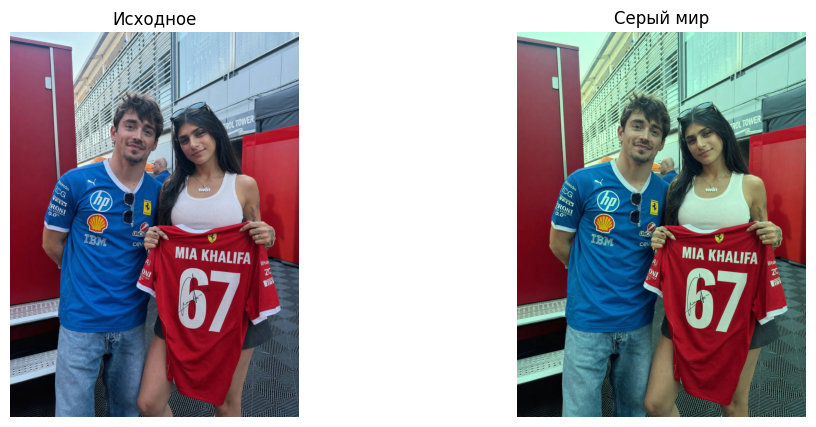

In [35]:
means = [image[:, :, c].mean() for c in range(3)]
avg = sum(means) / 3

gray_world_luts = [make_lut(lambda v: v * avg / means[c]) for c in range(3)]
gray_world_image = apply_luts(image, gray_world_luts)

print("Средние R, G, B до:", np.round(means, 1))
print("Средние R, G, B после:", np.round([gray_world_image[:, :, c].mean() for c in range(3)], 1))

plot_luts(gray_world_luts)
show_images([image, gray_world_image], ["Исходное", "Серый мир"])

3. По виду функции преобразования

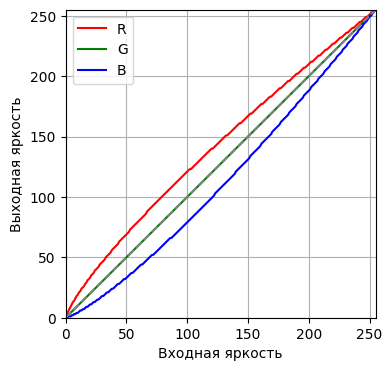

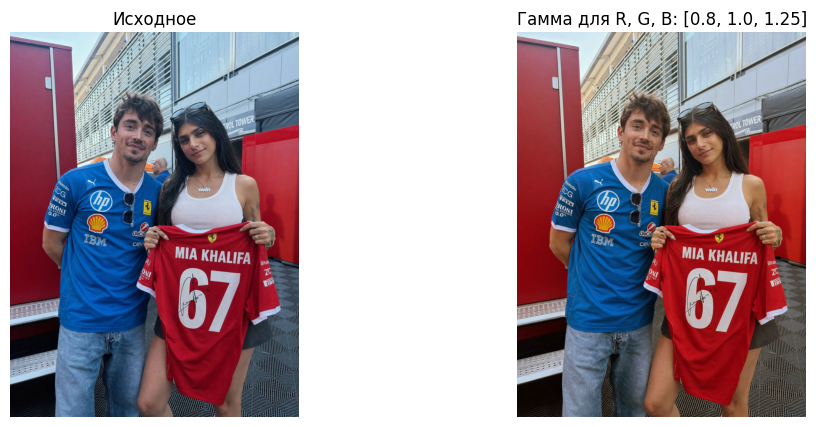

In [36]:
gammas = [0.8, 1.0, 1.25]

curve_luts = [make_lut(lambda v: 255 * (v / 255) ** gammas[c]) for c in range(3)]
curve_image = apply_luts(image, curve_luts)

plot_luts(curve_luts)
show_images([image, curve_image], ["Исходное", f"Гамма для R, G, B: {gammas}"])

2. Яркостная коррекция в интерактивном режиме по виду функции преобразования(необязательное дополнительное задание)

In [43]:
control_x = [0, 64, 128, 192, 255]

In [44]:
def make_sliders():
  return {
      f"y{i}": IntSlider(value=x, min=0, max=255, description=f"f({x})", continuous_update=False)
      for i, x in enumerate(control_x)
  }

In [42]:
def show_correction(img, lut, control_y, title):
  plt.figure(figsize=(15, 4))

  plt.subplot(1, 3, 1)
  plt.plot(range(256), lut)
  plt.scatter(control_x, control_y, color="red")
  plt.xlim(0, 255)
  plt.ylim(0, 255)
  plt.title(title)
  plt.grid()

  plt.subplot(1, 3, 2)
  plt.imshow(img, cmap="gray", vmin=0, vmax=255)
  plt.title("Исходное")
  plt.axis("off")

  plt.subplot(1, 3, 3)
  plt.imshow(cv2.LUT(img, lut), cmap="gray", vmin=0, vmax=255)
  plt.title("После коррекции")
  plt.axis("off")

  plt.show()

1. График функции кусочно линейный

In [40]:
@interact(**make_sliders())
def piecewise_linear(y0, y1, y2, y3, y4):
  control_y = [y0, y1, y2, y3, y4]
  lut = make_lut(lambda v: np.interp(v, control_x, control_y))
  show_correction(gray, lut, control_y, "Кусочно-линейная функция")

interactive(children=(IntSlider(value=0, continuous_update=False, description='f(0)', max=255), IntSlider(valu…

2. График функции интерполируется сплайном

In [41]:
@interact(**make_sliders())
def spline(y0, y1, y2, y3, y4):
  control_y = [y0, y1, y2, y3, y4]
  curve = CubicSpline(control_x, control_y)
  lut = make_lut(curve)
  show_correction(gray, lut, control_y, "Кубический сплайн")

interactive(children=(IntSlider(value=0, continuous_update=False, description='f(0)', max=255), IntSlider(valu…

3. Коррекция на основе гистограммы


In [47]:
def histogram(img):
  hist = np.zeros(256, dtype=np.int64)
  for v in range(256):
    hist[v] = np.sum(img == v)
  return hist

In [46]:
def show_with_histograms(images, titles):
  n = len(images)
  plt.figure(figsize=(6 * n, 8))

  for i in range(n):
    hist = histogram(images[i])
    cdf = np.cumsum(hist) / hist.sum()

    plt.subplot(2, n, i + 1)
    plt.imshow(images[i], cmap="gray", vmin=0, vmax=255)
    plt.title(titles[i])
    plt.axis("off")

    plt.subplot(2, n, n + i + 1)
    plt.bar(range(256), hist, width=1)
    plt.plot(range(256), cdf * hist.max(), color="red")
    plt.xlim(0, 255)

  plt.show()

1. Нормализация гистограммы

In [48]:
def normalization_lut(img, cut):
  hist = histogram(img)
  cdf = np.cumsum(hist) / hist.sum()
  low = np.argmax(cdf > cut)
  high = np.argmax(cdf >= 1 - cut)
  print(f"Отсечение {cut:.0%}: диапазон [{low}, {high}] растягивается до [0, 255]")
  return make_lut(lambda v: (v - low) * 255 / (high - low))

Отсечение 0%: диапазон [0, 255] растягивается до [0, 255]
Отсечение 1%: диапазон [5, 230] растягивается до [0, 255]


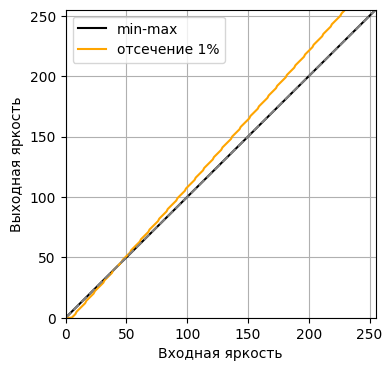

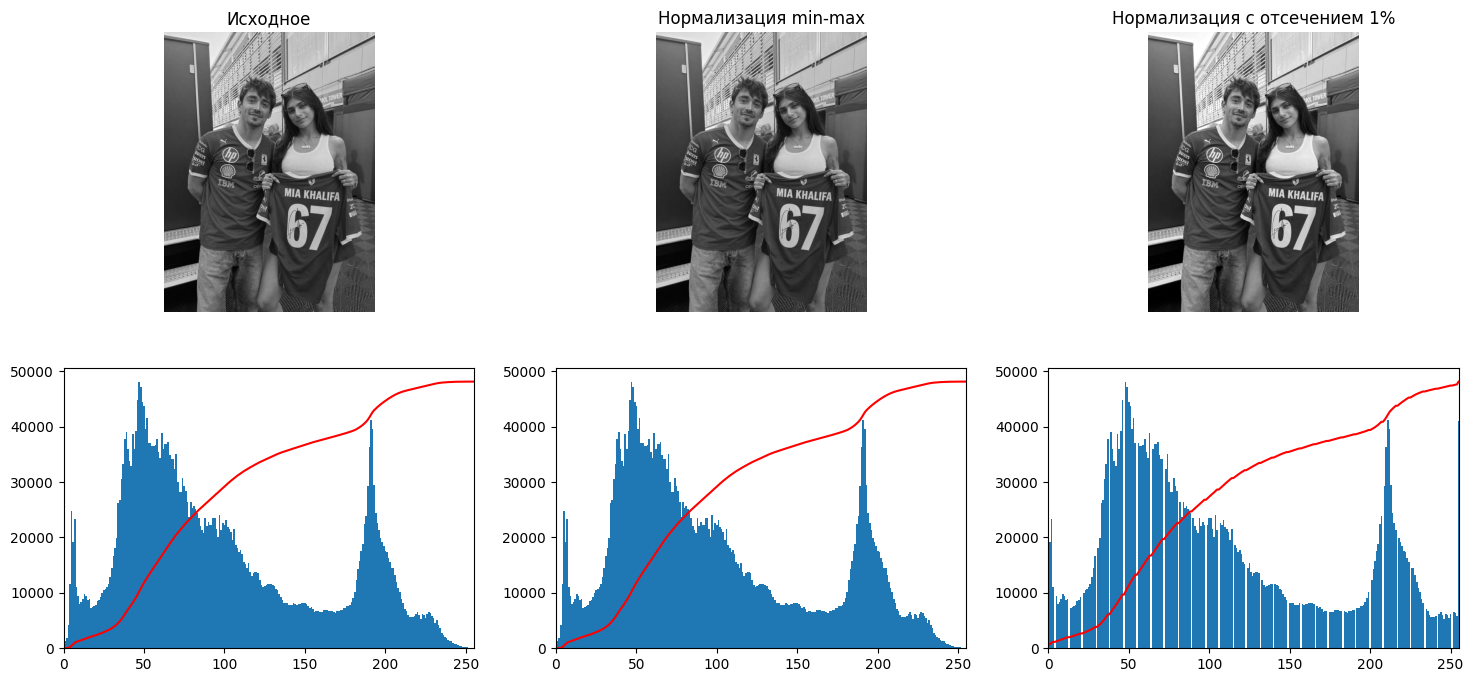

In [49]:
minmax_lut = normalization_lut(gray, 0)
clipped_lut = normalization_lut(gray, 0.01)

minmax_image = cv2.LUT(gray, minmax_lut)
clipped_image = cv2.LUT(gray, clipped_lut)

plot_luts([minmax_lut, clipped_lut], ["min-max", "отсечение 1%"], ["black", "orange"])
show_with_histograms(
    [gray, minmax_image, clipped_image],
    ["Исходное", "Нормализация min-max", "Нормализация с отсечением 1%"],
)

2. Эквализация гистограммы

In [50]:
def equalization_lut(img):
  hist = histogram(img)
  cdf = np.cumsum(hist) / hist.sum()
  cdf_min = cdf[cdf > 0].min()
  return make_lut(lambda v: (cdf[v] - cdf_min) / (1 - cdf_min) * 255)

Максимальное отличие от cv2.equalizeHist: 0


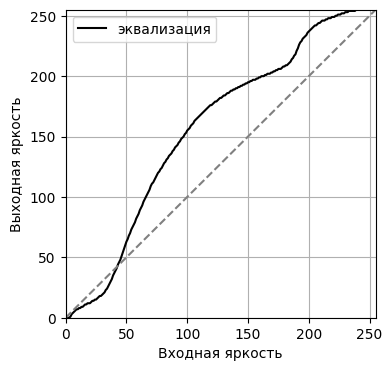

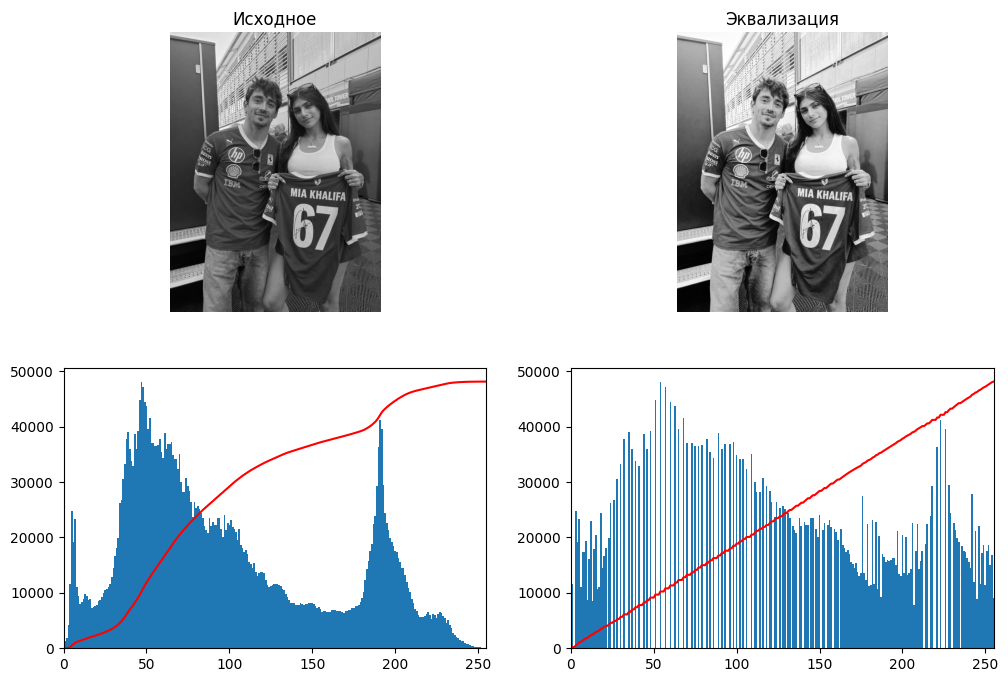

In [51]:
equalization = equalization_lut(gray)
equalized_image = cv2.LUT(gray, equalization)

opencv_image = cv2.equalizeHist(gray)
print("Максимальное отличие от cv2.equalizeHist:", np.abs(equalized_image.astype(int) - opencv_image).max())

plot_luts([equalization], ["эквализация"], ["black"])
show_with_histograms([gray, equalized_image], ["Исходное", "Эквализация"])